<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Atividade 2

>## Objetivos
>
>- Regressão linear com várias variáveis de entrada
>
>- (OK) Uma breve análise dos dados: o que cada variável significa, describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.
>
>- (OK) Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo). 
>
>- (OK) Padronização das entradas e da saída com StandardScaler ajustado só no treino.
>
>- (OK) Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.
>
>- (OK) RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.
>
>- (OK) Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?
>
>- Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?




## Importação das bibliotecas

In [117]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import seaborn as sns  # pyright: ignore[reportMissingModuleSource]
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

In [118]:
from sklearn.datasets import fetch_california_housing
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

## Análise exploratória dos dados

In [119]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [120]:
y.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [121]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [122]:
y.describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

In [123]:
print(f"X.shape: {X.shape}")
print(f"y.shape: {y.shape}")

X.shape: (20640, 8)
y.shape: (20640,)


In [124]:
#checar nulos
print("X.isnull().sum():")
print(f"{X.isnull().sum()}")
print("\ny.isnull().sum():")
print(f"{y.isnull().sum()}")
#checar dados duplicados
print("\nX.duplicated().sum():")
print(f"{X.duplicated().sum()}")
print("y.duplicated().sum():")
print(f"{y.duplicated().sum()}")


X.isnull().sum():
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

y.isnull().sum():
0

X.duplicated().sum():
0
y.duplicated().sum():
16798


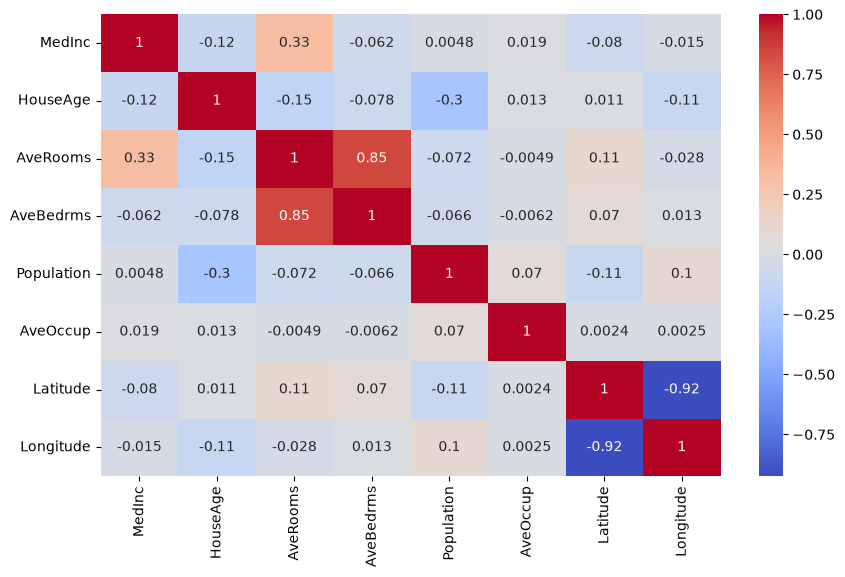

In [125]:
#heatmap das variáveis de entrada
plt.figure(figsize=(10, 6))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.show()

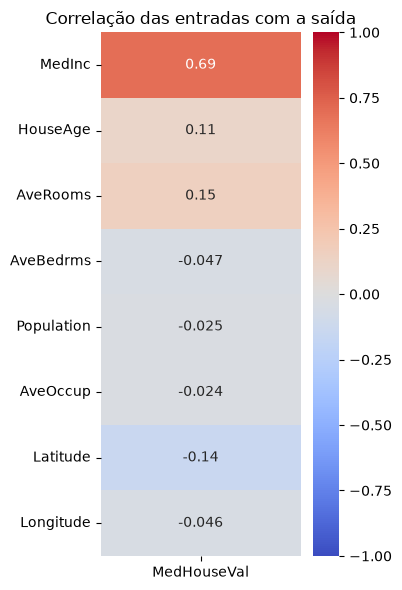

In [126]:
#heatmap da saída contra as variáveis de entrada
correlacoes = X.corrwith(y).to_frame(name=y.name)

plt.figure(figsize=(4, 6))
sns.heatmap(
    correlacoes,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlação das entradas com a saída")
plt.tight_layout()
plt.show()

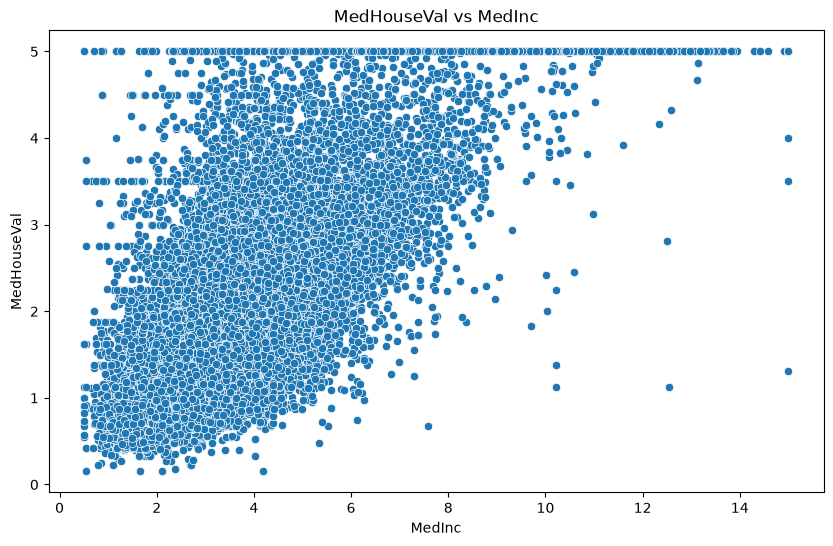

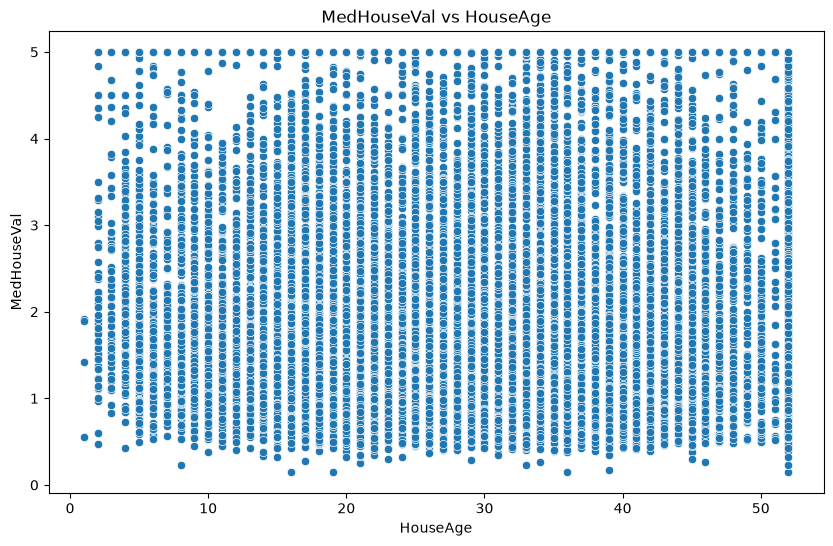

In [127]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X["MedInc"], y=y)
plt.title("MedHouseVal vs MedInc")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X["HouseAge"], y=y)
plt.title("MedHouseVal vs HouseAge")
plt.xlabel("HouseAge")
plt.ylabel("MedHouseVal")
plt.show()

Os dados usados são o **California Housing** (`sklearn.datasets.fetch_california_housing`): **20.640 grupos de quarteirões** do censo da Califórnia de 1990, com **8 variáveis de entrada** e o valor mediano das casas como saída. 

Cada linha é um grupo censitário, não uma casa isolada. 

Não há valores ausentes: todas as colunas e o alvo têm 20.640 observações. `X` tem forma `(20640, 8)` e `y` tem forma `(20640, 1)`.

Não há valores duplicados entre as entradas, e valores duplicados na saída não interferem na análise. 

| Variável | Papel | O que representa | Unidade | O que o `describe()` mostra |
|---|---|---|---|---|
| `MedInc` | Entrada | Renda mediana das famílias do grupo | Dezenas de milhares de dólares (8,33 ≈ US$ 83.300) | Média 3,87; vai de 0,50 a 15,00 (teto em 15) |
| `HouseAge` | Entrada | Idade mediana das casas | Anos | Média 28,6; vai de 1 a 52 (teto em 52) |
| `AveRooms` | Entrada | Média de cômodos por domicílio | Cômodos / domicílio | Média 5,43; máximo 141,9 (grupos com poucos domicílios inflam a média) |
| `AveBedrms` | Entrada | Média de quartos por domicílio | Quartos / domicílio | Média 1,10; máximo 34,1 (mesmo efeito de poucos domicílios) |
| `Population` | Entrada | População do grupo | Pessoas | Média 1.425; vai de 3 a 35.682 |
| `AveOccup` | Entrada | Média de moradores por domicílio | Pessoas / domicílio | Média 3,07; máximo 1.243 (outlier forte) |
| `Latitude` | Entrada | Latitude do grupo | Graus | De 32,54 a 41,95 (sul ao norte da Califórnia) |
| `Longitude` | Entrada | Longitude do grupo | Graus | De −124,35 a −114,31 (costa ao interior) |
| `MedHouseVal` (`y`) | Saída | Valor mediano das casas do grupo | Centenas de milhares de dólares (4,526 ≈ US$ 452.600) | Média 2,07; vai de 0,15 a 5,00 (teto em cerca de US$ 500.000) |

### Treino × validação

In [128]:
#concatenar X e y em um dataframe
df = pd.concat([X, y], axis=1)

In [129]:
#divisão em treino, validação e teste (70/15/15)
x_raw = df[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']].to_numpy()
y_raw = df[['MedHouseVal']].to_numpy()

x_train_raw, x_temp, y_train_raw, y_temp = train_test_split(
    x_raw, y_raw, test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42)

print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape, ' teste:', x_test_raw.shape)

treino: (14448, 8)  validação: (3096, 8)  teste: (3096, 8)


### Normalização

In [130]:
#Padronização das entradas e da saída com StandardScaler ajustado só no treino.

x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# tensores (sem requires_grad: são dados, não parâmetros)
x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val.shape)
print('x_test: ', x_test.shape, ' y_test: ', y_test.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])  y_test:  torch.Size([3096, 1])


## Modelo

In [131]:
model = nn.Linear(8, 1)
print("pesos (w1..w8):", model.weight)
print("bias (w0):     ", model.bias)

pesos (w1..w8): Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias (w0):      Parameter containing:
tensor([0.1229], requires_grad=True)


### Testando o predict da rede

In [132]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [133]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

In [134]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação

In [135]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [136]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

In [137]:
n_epochs = 120
w0_list = []
w_list = []
train_losses = []
val_losses = []
test_losses = []

for epoch in range(n_epochs):
    w0_list.append(model.bias.item())
    w_list.append(model.weight.detach().clone()) #unica mudança em relação à outra atividade, pois item() não funciona com as 8 entradas 

    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    test_loss = validate_epoch(model, criterion, x_test, y_test)
    test_losses.append(test_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}, Test Loss: {test_loss:.6f}")

Epoch[20/120], Train Loss: 0.402168, Val Loss: 0.413673, Test Loss: 0.383886
Epoch[40/120], Train Loss: 0.392304, Val Loss: 0.405145, Test Loss: 0.384089
Epoch[60/120], Train Loss: 0.390904, Val Loss: 0.403969, Test Loss: 0.386646
Epoch[80/120], Train Loss: 0.390696, Val Loss: 0.403794, Test Loss: 0.387825
Epoch[100/120], Train Loss: 0.390662, Val Loss: 0.403759, Test Loss: 0.388237
Epoch[120/120], Train Loss: 0.390656, Val Loss: 0.403746, Test Loss: 0.388355


### Curvas de custo de treino, validação e teste

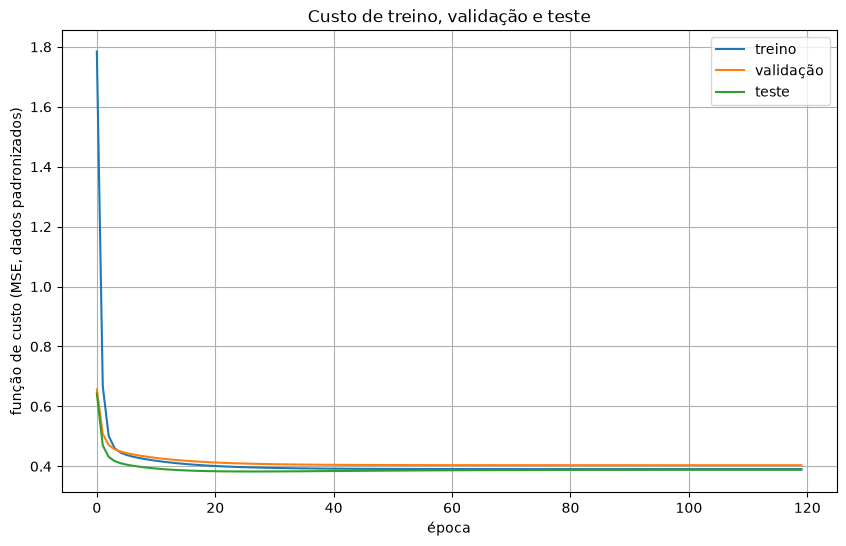

In [138]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label="treino")
plt.plot(range(n_epochs), val_losses, label="validação")
plt.plot(range(n_epochs), test_losses, label="teste")
plt.xlabel("época")
plt.ylabel("função de custo (MSE, dados padronizados)")
plt.title("Custo de treino, validação e teste")
plt.legend()
plt.grid(True)
plt.show()

### Previsto contra real

- Não realizei um plot/gráfico para comparar pois as 8 variáveis tornam a visualização muito difícil.

In [139]:
model.eval()
with torch.no_grad():
    y_test_pred = model(x_test)

y_real = y_test_raw.ravel() * 100_000
y_prev = y_scaler.inverse_transform(y_test_pred.numpy()).ravel() * 100_000

comparacao = pd.DataFrame({
    "real (US$)": y_real,
    "previsto (US$)": y_prev,
    "erro (US$)": y_prev - y_real,
}).round(0)

print(comparacao.head(10).to_string(index=False))
print(f"\nerro médio absoluto: US$ {np.abs(y_prev - y_real).mean():,.0f}")

 real (US$)  previsto (US$)  erro (US$)
   100000.0        138717.0     38717.0
   118800.0         80698.0    -38102.0
   376100.0        203867.0   -172233.0
   200000.0        232002.0     32002.0
    95200.0        194990.0     99790.0
   128500.0        160425.0     31925.0
   261300.0        265515.0      4215.0
   179400.0        235854.0     56454.0
   407000.0        346904.0    -60096.0
   175000.0        136906.0    -38094.0

erro médio absoluto: US$ 52,098


### Cálculo RMSE

In [140]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())

mse_test = criterion(
    torch.from_numpy(y_pred_test_raw).float(),
    torch.from_numpy(y_test_raw).float(),
)
rmse_test = torch.sqrt(mse_test).item()

y_base = np.full_like(y_test_raw, y_train_raw.mean())
rmse_base = np.sqrt(np.mean((y_test_raw - y_base) ** 2))

modelo_em_dolares = 100_000
print(f"RMSE do teste:    US$ {rmse_test * modelo_em_dolares:,.0f}")
print(f"RMSE do baseline: US$ {rmse_base * modelo_em_dolares:,.0f}")
print(f"preço médio do treino: US$ {y_train_raw.mean() * modelo_em_dolares:,.0f}")

RMSE do teste:    US$ 72,130
RMSE do baseline: US$ 114,992
preço médio do treino: US$ 206,924


### Parâmetros treinados (na escala padronizada)

In [141]:
nomes = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
]
pesos = model.weight.detach().numpy().ravel()

for nome, peso in sorted(zip(nomes, pesos), key=lambda par: par[1], reverse=True):
    print(f"{nome:12} {peso:+.3f}")

MedInc       +0.735
AveBedrms    +0.302
HouseAge     +0.106
Population   -0.001
AveOccup     -0.036
AveRooms     -0.260
Longitude    -0.747
Latitude     -0.768


Conclusão sobre os parâmetros:
- O maior valor positivo (MedInc) é a variável que mais aumenta o preço previsto, e o mais negativo (Latitude, mas Longitude também tem um comportamento bem parecido, pode ter haver com a localização especifica dos imóveis) é a que mais diminui.

- Essa comparação só faz sentido com a padronização devido às escalas diferentes entre as variáveis de entrada, sem essa padronização a comparação não teria a mesma leitura.

- Um detalhe estranho: achei que AveBedrms fosse ter um comportamento parecido com AveRooms, pois mais cômodos tem correlação positiva com mais quartos, mas isso não ocorreu.

## Conclusão

- O modelo linear com 8 entradas teve um resultado bom, no plot dos custos entre treino, validação e teste, todas as curvas descem juntas e depois estabilizam, dá pra notar que o modelo não apenas memorizou os dados de treino, pois os dados de teste também mostraram um custo similar.

- O modelo parece reduzir bastante o erro em relação a prever a média de um preço, mas devido ao tamanho/escala dos valores ainda é um erro considerável. Não acho que seria o ideal ainda.

- Acho que a melhor forma para melhorar o modelo seria utilizar um modelo de regressão não linear, um modelo linear me parece ineficaz devido à quantidade de entradas, é como se o modelo não conseguisse traduzir toda informação das entradas.

- OBS: aumentar o "período de treino" não melhoraria o modelo, pois no cálculo de custos as curvas já estabilizaram.